# D5 – Mini-projet : une série temporelle

**Python numérique – devoir n° 5 – à rendre pour le dimanche 18 octobre 2026, 23 h 59** (la séance 6 est le mardi 20)

Bienvenue dans votre cinquième devoir ! Nous allons y mettre en œuvre les notions vues en séance 5 : `to_datetime`, `DatetimeIndex`, la sélection par dates, `resample`, `rolling`, `df.plot` et les figures à plusieurs sous-graphiques avec `matplotlib`. C'est aussi un mini-projet : la dernière partie est ouverte, et c'est vous qui choisissez la question à laquelle répondre.

Durée indicative : 1 h 30.

````{admonition} Consignes de rendu
:class: important

* Ce notebook reste dans le dossier `D5/` de votre dépôt `pe-homework` (celui que le zip du sujet a créé en se dézippant), avec ses figures à côté, puis il doit être **commité et poussé** (`git add`, `git commit`, `git push`) avant la deadline. Attention, c'est la **date du commit** qui fait foi, pas celle du push ; le nom du fichier, lui, n'a pas d'importance (`sujet.ipynb` convient très bien). Le dossier `data/` livré avec le sujet reste lui aussi dans `D5/` : `git add D5` embarque tout le dossier, et c'est très bien ainsi (il ne pèse que quelques kilo-octets).
* Juste avant de rendre, **pensez à ré-exécuter toutes les cellules** via *Kernel → Restart Kernel and Run All Cells* : toutes doivent s'exécuter dans l'ordre et sans erreur. En effet, un notebook qui plante à mi-chemin sera corrigé jusqu'à l'erreur…
* Le notebook lit les données dans `data/comptage-velos.csv` (chemin relatif) ; la figure `serie.png` est quant à elle écrite dans le dossier du notebook.
* Les cellules `# votre code` sont à compléter ; vous pouvez ajouter autant de cellules que vous le souhaitez. Les cellules de test (`assert`) sont là pour vous aider : si elles passent sans erreur, c'est bon signe. Ne les modifiez pas !
* Répondez aux questions "en français" dans une cellule *Markdown*, en deux ou trois phrases. Dans ce devoir, la rédaction compte autant que le code.
````

````{admonition} Ce qui est autorisé
:class: note

* La documentation de `pandas` / `matplotlib`, les notebooks du cours, vos notes.
* Les assistants IA sont tolérés, avec la règle habituelle : **vous devez être capable d'expliquer chaque ligne que vous rendez**, et je pourrai vous demander de le faire à l'oral en séance. Le devoir est individuel.
* En revanche, pas de boucle `for` sur les lignes de la série : tout se fait avec les opérations `pandas`.
````

````{admonition} Les données
:class: warning

`data/comptage-velos.csv` contient le nombre de vélos comptés chaque jour par un compteur automatique installé sur une piste cyclable parisienne, du 1er janvier 2023 au 31 décembre 2024 : une colonne `date` (texte `AAAA-MM-JJ`) et une colonne `comptage`, séparées par `;`.

Attention, **ces données sont simulées** : je les ai produites avec le script `data/generate.py`, en fixant la graine afin que tout le monde travaille sur les mêmes valeurs. Vous pouvez le lire, mais seulement *après* avoir fait le devoir ! Elles ont cependant l'allure de vraies données de comptage, défauts compris : le fichier n'est pas trié, certaines lignes sont en double, certains jours n'ont pas de mesure, et le capteur a eu au moins deux ratés. Ainsi, comme dans la vraie vie, vous allez d'abord nettoyer, puis analyser.
````

## Barème

| Exercice | Contenu | Points |
|---|---|---|
| 1 | Chargement, index temporel, diagnostic et nettoyage | 6 |
| 2 | Rééchantillonnage (`resample`) et lissage (`rolling`) | 4 |
| 3 | Profils hebdomadaire et mensuel, 2023 vs 2024 | 4 |
| 4 | Figure à deux sous-graphiques `serie.png` | 3 |
| 5 | Question ouverte : une question, une figure, trois lignes de conclusion | 3 |
| **Total** | | **20** |
| Bonus | Jour le plus creux, croissance annuelle | +2 |

*Inspiré des exercices de <https://numerique-exos.info-mines.paris>.*

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Exercice 1 – Charger, indexer, nettoyer (6 pts)

**1.a** Lisez le fichier dans une `DataFrame` `df` et affichez `df.info()`. Quel est le type de la colonne `date` ? Pourquoi n'est-ce pas satisfaisant ? Le fichier est-il trié par date ?

In [2]:
df = pd.read_csv("data/comptage-velos.csv", sep=";")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 734 entries, 0 to 733
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      734 non-null    str    
 1   comptage  726 non-null    float64
dtypes: float64(1), str(1)
memory usage: 11.6 KB


In [3]:
assert df.shape == (734, 2)
assert list(df.columns) == ["date", "comptage"]
print("ok")

ok


**1.b** Construisez maintenant la `Series` `brut` : les comptages indexés par la date, avec un vrai `DatetimeIndex`, triée par date et en flottants.

In [4]:
df['date'] = pd.to_datetime(df['date'], format="%Y-%m-%d")
brut = df.set_index('date')['comptage'].astype(float)
brut = brut.sort_index()
print(brut)

date
2023-01-01     304.0
2023-01-02    1658.0
2023-01-03    1450.0
2023-01-04    1902.0
2023-01-05    1715.0
               ...  
2024-12-27    1906.0
2024-12-28    1186.0
2024-12-29    1040.0
2024-12-30    1900.0
2024-12-31    2126.0
Name: comptage, Length: 734, dtype: float64


In [5]:
assert isinstance(brut, pd.Series)
assert isinstance(brut.index, pd.DatetimeIndex)
assert brut.index.is_monotonic_increasing
assert len(brut) == 734
assert brut.index[0] == pd.Timestamp("2023-01-01") and brut.index[-1] == pd.Timestamp("2024-12-31")
print("ok")

ok


````{admonition} Pas encore vu en cours : duplicated()
:class: note

`serie.duplicated()` — ou `index.duplicated()` — renvoie un tableau de booléens de même longueur, avec `True` sur les valeurs *déjà rencontrées plus haut* : la première occurrence vaut `False`, les suivantes `True`. Ainsi, sur `[3, 1, 3, 3]`, on obtient `[False, False, True, True]`. Combiné à `~`, il permet donc de ne garder que la première occurrence de chaque valeur.
````

**1.c** Place au diagnostic. Répondez d'abord par du code, puis résumez vos observations dans une cellule Markdown :

* combien de dates apparaissent en double ? lesquelles ?
* combien de valeurs manquantes ? quels jours ?
* observez `brut.describe()` : le minimum et le maximum vous semblent-ils plausibles pour un compteur vélo ? Affichez les jours dont le comptage est nul, et ceux dont le comptage dépasse 3 fois la médiane.

In [6]:
print(f"Il y a {brut.index.duplicated().sum()} date en double")
print("Les dates en question:")
print(brut[brut.index.duplicated()].index)
print(f"Il manque {brut.isna().sum()} valeurs, qui sont:")
print(brut[brut.isna()].index)
print(brut.describe())
print("Jour avec comptage nul: " + str(brut[brut == 0].index))
print("Jour avec comptage plus que trois fois la médiane: " + str(brut[brut > 3 * brut.median()].index))

Il y a 3 date en double
Les dates en question:
DatetimeIndex(['2023-05-25', '2023-12-21', '2024-02-27'], dtype='datetime64[us]', name='date', freq=None)
Il manque 8 valeurs, qui sont:
DatetimeIndex(['2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09',
               '2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22'],
              dtype='datetime64[us]', name='date', freq=None)
count      726.000000
mean      2454.612948
std       1646.281515
min          0.000000
25%       1770.250000
50%       2301.000000
75%       3090.000000
max      39660.000000
Name: comptage, dtype: float64
Jour avec comptage nul: DatetimeIndex(['2024-06-27'], dtype='datetime64[us]', name='date', freq=None)
Jour avec comptage plus que trois fois la médiane: DatetimeIndex(['2024-07-04'], dtype='datetime64[us]', name='date', freq=None)


On remarque que il y a 3 date en double, le 25/05/2023, le 21/12/2023, et le 27/02/2024, et 8 veluers manquantes: '2023-02-23', '2023-06-25', '2023-12-01', '2024-01-09','2024-02-08', '2024-03-13', '2024-11-17', '2024-11-22'. Dans la description de brut, le minimum semble trop faible pour un compteur vélo (0 secondes, soit pas de vélo le 27/06/2024, le compteur n'aurais pas du commencer), et le maximum beaucoup trop élevé (39660 le 04/07/2024, soit plus de 10 fois plus la moyenne, le seul aussi élevé de trés loins et qui semble impossible d'avoir un compteur aussi élevé en une seul journée)

In [7]:
assert brut.index.duplicated().sum() == 3
assert brut.isna().sum() == 8
assert (brut == 0).sum() == 1
assert (brut > 3 * brut.median()).sum() == 1
print("ok")

ok


````{admonition} Pas encore vu en cours : interpolate()
:class: note

`serie.interpolate()` remplace chaque `NaN` par une valeur déduite de ses voisins non manquants, par interpolation linéaire par défaut : sur `[10, NaN, NaN, 40]`, on obtient `[10, 20, 30, 40]`. C'est l'alternative à `fillna` quand les données ont un ordre naturel, comme ici le temps.
````

**1.d** Passons au nettoyage. Construisez la série propre `velos`, en trois temps :

1. supprimez les doublons d'index en ne gardant que la première occurrence (`duplicated()`) ;
2. remplacez les deux valeurs aberrantes (comptage nul ou supérieur à 3 fois la médiane) par `NaN` ;
3. remplissez tous les `NaN` (les 8 jours vides + les 2 aberrants) par interpolation linéaire.

Vérifiez enfin que `velos` a exactement une valeur par jour du 1er janvier 2023 au 31 décembre 2024 (soit 731 jours), et plus aucun `NaN`.

In [8]:
velos = brut[~brut.index.duplicated(keep='first')]
velos = velos.mask((velos == 0) | (velos > 3 * brut.median()))
velos = velos.interpolate(method='linear')

#test de une valeur par jour, sans NaN
assert len(velos) == 731
assert velos.isna().sum() == 0
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()

In [9]:
assert len(velos) == 731
assert velos.isna().sum() == 0
assert not velos.index.duplicated().any()
assert (velos.index == pd.date_range("2023-01-01", "2024-12-31", freq="D")).all()
assert velos.min() > 100 and velos.max() < 6000
assert abs(velos.loc["2024-07-04"] - (velos.loc["2024-07-03"] + velos.loc["2024-07-05"]) / 2) < 1
print("ok")

ok


## Exercice 2 – Rééchantillonner et lisser (4 pts)

**2.a** Calculez :

* `hebdo` : la moyenne par semaine ;
* `mensuel` : la moyenne par mois (l'alias de fréquence des mois est `"ME"`, *month end*, depuis pandas 2.2 ; `"M"` si votre pandas est plus ancien) ;
* `annuel` : le **total** par année.

Combien de lignes ont `hebdo` et `mensuel` ? Pourquoi `hebdo` n'a-t-il pas exactement 731 / 7 lignes ?

In [10]:

hebdo = velos.resample('W').mean()
mensuel = velos.resample('ME').mean()
annuel = velos.resample('YE').sum()
print(velos.index.day_name())
print(hebdo.shape)
print(mensuel.shape)

Index(['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday',
       'Saturday', 'Sunday', 'Monday', 'Tuesday',
       ...
       'Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday',
       'Saturday', 'Sunday', 'Monday', 'Tuesday'],
      dtype='str', name='date', length=731)
(106,)
(24,)


hebdo a 106 lignes, et mensuel 24 lignes. hedbo n'a pas exactement 731/7 lignes parce qu'on commence un Dimanche, et on fini un Mardi, donc la premiere semaine et la derniere semaine compte moins que 7 jours (1 jour pour la premiere, 2 pour la derniere)

In [11]:
assert len(hebdo) == 106 and len(mensuel) == 24 and len(annuel) == 2
assert abs(mensuel.sum() * 30.4 - velos.sum()) / velos.sum() < 0.05
assert annuel.iloc[1] > annuel.iloc[0]
print("ok")

ok


**2.b** Calculez `lisse`, la moyenne glissante **centrée** sur 7 jours. Combien de `NaN` contient-elle, et où ? Pourquoi 7 jours est-il un bon choix de fenêtre pour cette série ? Enfin, tracez `velos` (trait fin, transparent) et `lisse` sur le même graphique, avec la méthode `.plot()` des `Series`.

6
DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[us]', name='date', freq=None)


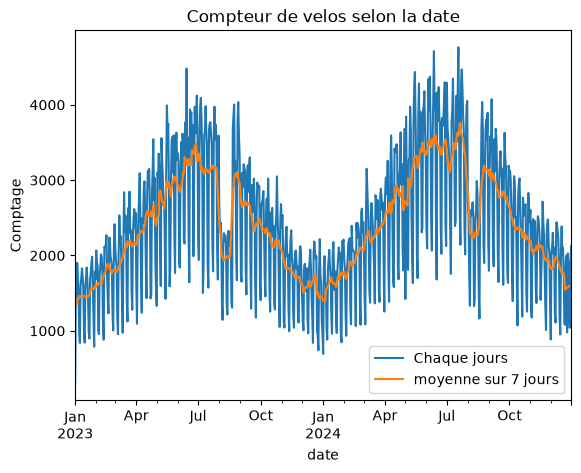

In [12]:
lisse = velos.rolling(7, center=True).mean()
print(lisse.isna().sum())
print(lisse[lisse.isna()].index)
velos.plot(label="Chaque jours")
lisse.plot(label="moyenne sur 7 jours")
plt.ylabel("Comptage")
plt.title("Compteur de velos selon la date")
plt.legend()
plt.show()

La série lisse contient 6 valeurs NaN. Ils se situent aux extrémités : les 3 premiers jours (du 1er au 3 janvier 2023) et les 3 derniers jours (du 29 au 31 décembre 2024), car une fenêtre centrée de 7 jours ne peut pas être calculée sans 3 points en amont et 3 points en aval. Une période de 7 jours correspond à la durée d'une semaine, donc moins de variete due à la saisonnalité hebdomadaire, mais ça conserve les tendances à moyen terme.

In [13]:
assert len(lisse) == 731
assert lisse.isna().sum() == 6
assert abs(lisse.loc["2023-06-15"] - velos.loc["2023-06-12":"2023-06-18"].mean()) < 1e-9
print("ok")

ok


## Exercice 3 – Profils (4 pts)

**3.a** Commençons par le profil hebdomadaire : calculez `profil_semaine`, la moyenne des comptages pour chaque jour de la semaine, avec 0 = lundi … 6 = dimanche. Remplacez ensuite l'index `0..6` par les noms des jours (`"lun"`, `"mar"`, … `"dim"`). De combien (en %) le dimanche est-il plus bas que la moyenne des jours de semaine (lundi à vendredi) ?

In [14]:
profil_semaine = velos.groupby(velos.index.dayofweek).mean()
profil_semaine.index = ["lun", "mar","mer","jeu","ven","sam","dim"]
print(((profil_semaine[["lun", "mar", "mer", "jeu", "ven"]].mean() - profil_semaine["dim"])/profil_semaine[["lun", "mar", "mer", "jeu", "ven"]].mean())*100)

49.83395691464415


Le dimanche est 49.8% plus bas que la moyenne des jours de semaine

In [15]:
assert profil_semaine.shape == (7,)
assert list(profil_semaine.index) == ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
assert profil_semaine["sam"] < 0.75 * profil_semaine["lun"]
assert profil_semaine["dim"] < profil_semaine["sam"]
print("ok")

ok


````{admonition} Pas encore vu en cours : idxmax et idxmin
:class: note

`serie.idxmax()` renvoie l'**étiquette** de la plus grande valeur (ici un numéro de mois), alors que `serie.max()` renvoie la valeur elle-même ; `idxmin` fait de même pour la plus petite. Sur une série indexée par des dates, on récupère donc directement le `Timestamp` du maximum.
````

**3.b** Intéressons-nous maintenant à la saisonnalité : calculez `profil_mois`, la moyenne pour chaque mois de l'année (1 à 12), les deux années confondues. Quel est le mois le plus chargé ? Et que se passe-t-il en août ?

In [16]:
profil_mois = velos.groupby(velos.index.month).mean()
print(profil_mois)
print(profil_mois.idxmax())

date
1     1547.806452
2     1845.000000
3     2144.024194
4     2585.300000
5     3013.000000
6     3313.183333
7     3285.483871
8     2535.774194
9     2693.766667
10    2309.419355
11    1924.308333
12    1657.911290
Name: comptage, dtype: float64
6


Le mois le plus charge est le mois de juin, avec une moyenne de 3313. En aout, on a une baisse notable de la moyenne du mois, surement due a la prise de congée pour les vacances d'été

In [17]:
assert profil_mois.shape == (12,) and list(profil_mois.index) == list(range(1, 13))
assert profil_mois.idxmax() in (6, 7)
assert profil_mois[8] < profil_mois[7] and profil_mois[8] < profil_mois[9]
assert profil_mois.idxmin() in (1, 12)
print("ok")

ok


**3.c** Opposons enfin 2023 à 2024 : avec la sélection par chaîne de date, calculez la moyenne journalière de chaque année, puis la croissance en % de 2023 à 2024 (variable `croissance`). Posez-vous ensuite la même question mois par mois : construisez la table `par_mois` de forme `(12, 2)` (lignes = mois, colonnes = années) — `unstack` peut aider — et repérez le mois où la progression a été la plus forte.

In [18]:
moy_2023 = velos['2023'].mean()
moy_2024 = velos['2024'].mean()
croissance = (moy_2024 - moy_2023) / moy_2023 * 100
print(croissance)
par_mois = velos.groupby([velos.index.month, velos.index.year]).mean().unstack()
par_mois.columns = [2023, 2024]
print(par_mois)
progression_mois = (par_mois[2024] - par_mois[2023]) / par_mois[2023] * 100
mois_max_prog = progression_mois.idxmax()
print(progression_mois)
print(f"Le mois où la progression a été la plus forte est le mois numéro {mois_max_prog}.")

10.481613797717293
             2023         2024
date                          
1     1451.612903  1644.000000
2     1755.160714  1931.741379
3     2053.516129  2234.532258
4     2393.466667  2777.133333
5     2849.903226  3176.096774
6     3223.133333  3403.233333
7     3091.870968  3479.096774
8     2454.193548  2617.354839
9     2537.033333  2850.500000
10    2232.225806  2386.612903
11    1816.400000  2032.216667
12    1548.564516  1767.258065
date
1     13.253333
2     10.060655
3      8.814936
4     16.029748
5     11.445776
6      5.587730
7     12.523996
8      6.648265
9     12.355638
10     6.916285
11    11.881561
12    14.122340
dtype: float64
Le mois où la progression a été la plus forte est le mois numéro 4.


In [19]:
assert 7 < croissance < 14
assert par_mois.shape == (12, 2)
assert list(par_mois.columns) == [2023, 2024]
assert (par_mois[2024] > par_mois[2023]).sum() >= 10
print("ok")

ok


## Exercice 4 – Figure à deux sous-graphiques (3 pts)

Construisez une figure `fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))` :

* en haut : la série journalière `velos` (trait fin, transparent) et la série lissée `lisse` (trait plus épais), avec une légende, un titre et un nom d'axe des ordonnées ;
* en bas : le profil hebdomadaire `profil_semaine` en barres, avec un titre et un nom d'axe des ordonnées.

Terminez par `fig.tight_layout()` et enregistrez dans `serie.png` (`fig.savefig`).

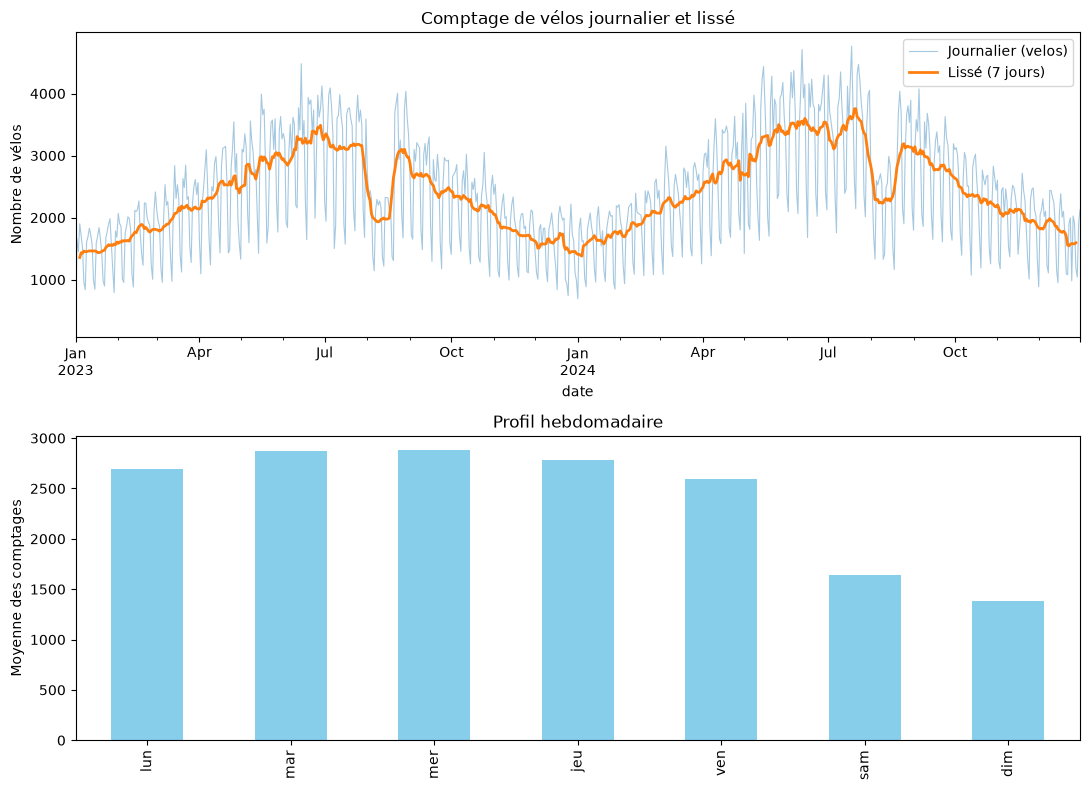

In [20]:
fig, (ax_haut, ax_bas) = plt.subplots(2, 1, figsize=(11, 8))
velos.plot(ax=ax_haut, alpha=0.4, linewidth=0.8, label="Journalier (velos)")
lisse.plot(ax=ax_haut, linewidth=2, label="Lissé (7 jours)")
ax_haut.set_title("Comptage de vélos journalier et lissé")
ax_haut.set_ylabel("Nombre de vélos")
ax_haut.legend()
profil_semaine.plot(kind="bar", ax=ax_bas, color="skyblue")
ax_bas.set_title("Profil hebdomadaire")
ax_bas.set_ylabel("Moyenne des comptages")
fig.tight_layout()
fig.savefig("serie.png")
plt.show()

In [21]:
assert os.path.exists("serie.png")
print("ok")

ok


## Exercice 5 – Question ouverte (3 pts)

C'est ici que vous prenez la main ! Choisissez **une** question sur cette série, puis répondez-y avec une figure (au moins une courbe ou un diagramme, légendée et titrée) et trois lignes de conclusion en Markdown. Voici quelques idées, mais une question à vous est la bienvenue :

* le creux d'août a-t-il la même ampleur en 2023 et en 2024 ?
* l'écart week-end / semaine est-il le même en été et en hiver ?
* quelle semaine de l'année est la plus chargée ? la plus creuse ? est-ce la même les deux années ?
* la croissance entre 2023 et 2024 est-elle uniforme sur l'année, ou concentrée sur certains mois ?
* que se passe-t-il autour des jours fériés que vous connaissez ?

Côté barème, je compte un point pour la pertinence de la méthode, un point pour une figure lisible et correcte, et un point pour une conclusion chiffrée et honnête.

Hiver semaine     1935.817829
Hiver week-end    1042.288462
Ete semaine       3493.465649
Ete week-end      1925.754717
dtype: float64


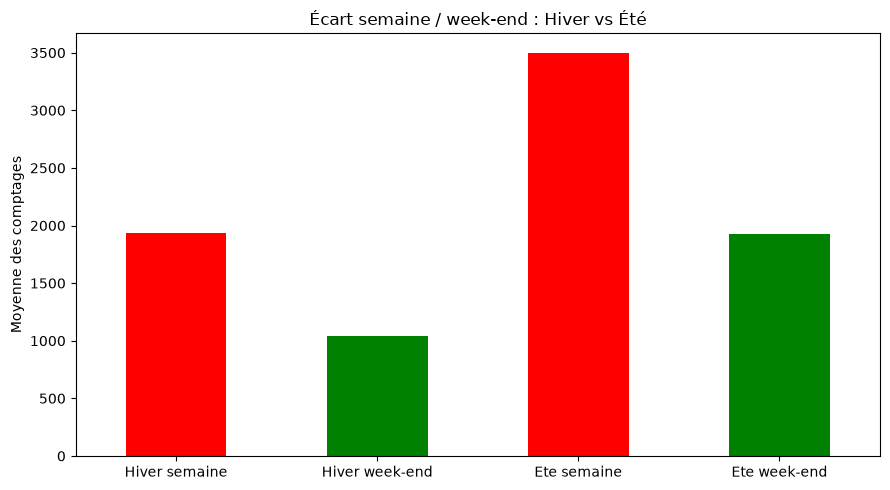

Ecart Hiver en pourcentage: 46.157719715257045 %
Ecart Ete en pourcentage: 44.875521600954386 %
Ecart Hiver en absolue: 893.5293679189028
Ecart Ete en absolue: 1567.7109318738296


In [22]:
hiver_mask = velos.index.month.isin([12, 1, 2])
ete_mask = velos.index.month.isin([6, 7, 8])
weekend_mask = velos.index.weekday >= 5
moyennes = {
    'Hiver semaine': velos[hiver_mask & ~weekend_mask].mean(),
    'Hiver week-end': velos[hiver_mask & weekend_mask].mean(),
    'Ete semaine': velos[ete_mask & ~weekend_mask].mean(),
    'Ete week-end': velos[ete_mask & weekend_mask].mean()
}
df_comparaison = pd.Series(moyennes)
print(df_comparaison)
fig, ax = plt.subplots(figsize=(9, 5))
df_comparaison.plot(kind='bar', ax=ax, color=['red', 'green', 'red', 'green'])
ax.set_title("Écart semaine / week-end : Hiver vs Été")
ax.set_ylabel("Moyenne des comptages")
plt.xticks(rotation=0)
fig.tight_layout()
plt.show()

print(f"Ecart Hiver en pourcentage: {abs(moyennes["Hiver semaine"] - moyennes["Hiver week-end"])/moyennes["Hiver semaine"] * 100} %")
print(f"Ecart Ete en pourcentage: {abs(moyennes["Ete semaine"] - moyennes["Ete week-end"])/moyennes["Ete semaine"] * 100} %")
print(f"Ecart Hiver en absolue: {abs(moyennes["Hiver semaine"] - moyennes["Hiver week-end"])}")
print(f"Ecart Ete en absolue: {abs(moyennes["Ete semaine"] - moyennes["Ete week-end"])}")



Hausse globale de la fréquentation en été : La moyenne des comptages en semaine passe de 1935,82 en hiver à 3 493,47 en été, et le week-end de 1 042,29 à 1 925,75, donc il y a une hausse global de la fréquentation en été, pour la semaine autant que le week-end. Les gens sortent moins en vélo quand il fait froid dehors.
Écarts relatifs similaires (en pourcentages) : L'écart entre la semaine et le week-end est de 46,16% en hiver (soit une baisse absolue de 893,53 passages) et de 44,88% en été (soit une baisse absolue de 1 567,71 passages). L'écart en volume absolu soit beaucoup plus élevé en été en raison d'un trafic global plus fort, la baisse relative entre les jours de la semaine et le week-end reste remarquablement stable d'une saison à l'autre, se stabilisant autour de 45%.

## Bonus (+2)

**Bo.1** Quel est le jour le plus creux de toute la série ? Et le plus chargé ? Pour chacun, donnez le jour de la semaine (`.day_name()`) et proposez une explication.

````{admonition} Pas encore vu en cours : pct_change
:class: note

`serie.pct_change()` renvoie la variation *relative* d'une valeur à la suivante : sur `[100, 110, 99]`, elle donne `[NaN, 0.10, -0.10]`. La première case vaut `NaN` faute de valeur précédente, et le résultat est une proportion, à multiplier par 100 pour l'exprimer en pourcentage.
````

**Bo.2** Calculez la croissance annuelle en % à partir des totaux annuels `annuel`. Pourquoi ce chiffre est-il légèrement différent de `croissance` (exercice 3.c) ?

In [23]:
date_min = velos.idxmin()
val_min = velos.min()
print(f"Jour le plus creux : {date_min.strftime('%Y-%m-%d')} ({date_min.day_name()}) avec {val_min} vélos")

date_max = velos.idxmax()
val_max = velos.max()
print(f"Jour le plus chargé : {date_max.strftime('%Y-%m-%d')} ({date_max.day_name()}) avec {val_max} vélos")
croissance_annuel = annuel.pct_change().iloc[-1] * 100
print(f"Croissance annuelle : {croissance_annuel}%")

Jour le plus creux : 2023-01-01 (Sunday) avec 304.0 vélos
Jour le plus chargé : 2024-07-18 (Thursday) avec 4764.0 vélos
Croissance annuelle : 10.784303150587737%


Le jour le plus creux: Un dimanche, le jour du nouvelle ans, donc un jour férié d'hiver après une grosse fête la veille, qui tombe en plus un jour de week-end (généralement moins fréquenté). Les gens ne vont pas au travail et préfère rester chez eux pour se reposer. 

Le jour le plus chargé: Un jour de semaine en plein été, en 2024, 3 facteurs qui statistiquement augmente le nombre de velos et qui explique pourquoi c'est le jour le plus chargé. 

L'année 2024 est bissextile. Le calcul de l'exercice 3.c reposait sur la moyenne journalière (somme divisée par le nombre de jours de chaque année), tandis que le calcul à partir de annuel compare les totaux bruts. L'ajout d'un jour de comptage en 2024 impacte le total annuel global par rapport à la moyenne par jour. 

Bon courage à tous ! Pour toute question sur le sujet, vous pouvez me contacter par email : [raphael@imagine-app.fr](mailto:raphael@imagine-app.fr).

Au plaisir de vous lire,

votre responsable de cours, Raphael Prasquier
(sujet conçu par Aurélien Noce)